# Baseline ResNet-18 Experimental Pipeline

### Imported Required Libraries

In [8]:
!pip install torch torchvision torchaudio
!pip install matplotlib pandas numpy codecarbon

### Dataset Loading and Preprocessing

In [11]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Define image transformations
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Load training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Load test dataset
test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)
# CIFAR-10 class names
classes = (
    'plane', 'car', 'bird', 'cat',
    'deer', 'dog', 'frog', 'horse',
    'ship', 'truck'
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Files already downloaded and verified
Files already downloaded and verified
Training samples: 50000
Testing samples: 10000


### Data Visualization

Matplotlib is building the font cache; this may take a moment.


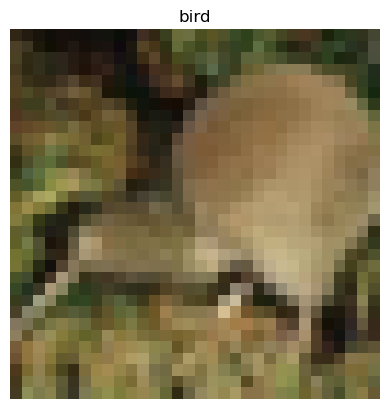

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Get a batch of images
images, labels = next(iter(train_loader))

# Show one image
img = images[0] / 2 + 0.5  # unnormalize
npimg = img.numpy()

plt.imshow(np.transpose(npimg, (1, 2, 0)))
plt.title(classes[labels[0]])
plt.axis('off')
plt.show()

# Baseline ResNet-18 Model

In [13]:
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

# Select GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load ResNet-18 architecture
model = models.resnet18(weights=None)

# Replace final classification layer for CIFAR-10's 10 classes
model.fc = nn.Linear(model.fc.in_features, 10)

# Move model to selected device
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

Device: cpu
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inpl

In [14]:
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

# Select GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load ResNet-18 architecture
model = models.resnet18(weights=None)

# Replace final classification layer for CIFAR-10's 10 classes
model.fc = nn.Linear(model.fc.in_features, 10)

# Move model to selected device
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

Device: cpu
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inpl

### Baseline Model Training

In [15]:
import time

num_epochs = 5

# Store training metrics for later comparison
train_losses = []
train_accuracies = []

start_time = time.time()

for epoch in range(num_epochs):
    model.train()
    
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        # Reset gradients from previous batch
        optimizer.zero_grad()
        
        # Forward pass and loss calculation
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backpropagation and parameter update
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
        _, predicted = torch.max(outputs, 1)
        total_samples += labels.size(0)
        correct_predictions += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct_predictions / total_samples
    
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] "
          f"Loss: {epoch_loss:.4f} "
          f"Training Accuracy: {epoch_accuracy:.2f}%")

end_time = time.time()
training_time = end_time - start_time

print(f"\nTotal training time: {training_time:.2f} seconds")

Epoch [1/5] Loss: 1.3820 Training Accuracy: 50.40%
Epoch [2/5] Loss: 0.9838 Training Accuracy: 65.54%
Epoch [3/5] Loss: 0.8081 Training Accuracy: 71.88%
Epoch [4/5] Loss: 0.6771 Training Accuracy: 76.54%
Epoch [5/5] Loss: 0.5686 Training Accuracy: 80.20%

Total training time: 619.87 seconds


### Baseline Model Evaluation

In [16]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 75.52%


### Carbon Emissions Tracking

In [17]:
from codecarbon import EmissionsTracker

In [18]:
tracker = EmissionsTracker()
tracker.start()

# training loop

emissions = tracker.stop()

print("CO2 emissions:", emissions, "kg")

[codecarbon WARNING @ 15:50:40] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 15:50:40] [setup] RAM Tracking...
[codecarbon INFO @ 15:50:40] [setup] CPU Tracking...
[codecarbon INFO @ 15:50:40] Tracking Intel CPU via RAPL interface
[codecarbon INFO @ 15:50:43] 	RAPL - Using 6 package domain(s) for CPU power measurement
[codecarbon INFO @ 15:50:43] 	RAPL - Selected 2 unique RAPL domain(s) after deduplication
[codecarbon INFO @ 15:50:43] 	RAPL - Monitoring domain 'package-1' (displayed as 'Processor Energy Delta_0(kWh)') via MSR at /sys/class/powercap/intel-rapl/subsystem/intel-rapl/intel-rapl:0/energy_uj
[codecarbon INFO @ 15:50:43] 	RAPL - Monitoring domain 'package-0' (displayed as 'Processor Energy Delta_1(kWh)') via MSR at /sys/class/powercap/intel-rapl/subsystem/intel-rapl/intel-rapl:1/energy_uj
[codecarbon INFO @ 15:50:43] [setup] GPU Tracking...
[codecarbon INFO @ 15:50:43] No GPU found.
[codecarbon INFO @ 15:50:43] The below tracking me

CO2 emissions: 9.75832119411401e-09 kg


### Baseline Results Summary

In [19]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Baseline ResNet-18"],
    "Training Accuracy (%)": [80.20],
    "Test Accuracy (%)": [75.52],
    "Training Time (s)": [619.87],
    "CO2 Emissions (kg)": [9.75832119411401e-09]
})

results

,Model,Training Accuracy (%),Test Accuracy (%),Training Time (s),CO2 Emissions (kg)
0,Baseline ResNet-18,80.2,75.52,619.87,9.758321e-09


In [20]:
results.to_csv("baseline_results.csv", index=False)

print("Results saved successfully.")

Results saved successfully.


### Pruned ResNet-18 Model

In [21]:
torch.save(model.state_dict(), "baseline_resnet18.pth")
print("Baseline model saved.")

Baseline model saved.


In [23]:
import torch.nn.utils.prune as prune

# Apply unstructured pruning to convolutional and linear layers
pruning_amount = 0.20

for name, module in model.named_modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        prune.l1_unstructured(module, name="weight", amount=pruning_amount)

print("Pruning applied to ResNet-18 model.")

Pruning applied to ResNet-18 model.


In [24]:
total_params = 0
zero_params = 0

for name, module in model.named_modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        weight = module.weight
        total_params += weight.nelement()
        zero_params += torch.sum(weight == 0).item()

sparsity = 100 * zero_params / total_params

print(f"Model sparsity after pruning: {sparsity:.2f}%")

Model sparsity after pruning: 20.00%


### Evaluation of Pruned Model

In [25]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

pruned_test_accuracy = 100 * correct / total

print(f"Pruned Test Accuracy: {pruned_test_accuracy:.2f}%")

Pruned Test Accuracy: 75.26%


### Pruned Results Summary

In [26]:
import pandas as pd

comparison_results = pd.DataFrame({
    "Model": ["Baseline ResNet-18", "Pruned ResNet-18"],
    "Test Accuracy (%)": [75.52, 75.26],
    "Sparsity (%)": [0, 20]
})

comparison_results

,Model,Test Accuracy (%),Sparsity (%)
0,Baseline ResNet-18,75.52,0
1,Pruned ResNet-18,75.26,20


In [27]:
comparison_results.to_csv(
    "baseline_vs_pruned_results.csv",
    index=False
)

print("Comparison table saved.")

Comparison table saved.


#### Initial Observation

Applying 20% unstructured pruning reduced model parameters while maintaining similar predictive performance. Test accuracy decreased by only 0.26 percentage points compared with the baseline model.

### Quantized ResNet-18 Model

In [28]:
import torch.quantization as quantization

quantized_model = torch.quantization.quantize_dynamic(
    model,
    {torch.nn.Linear},
    dtype=torch.qint8
)

print("Quantization applied successfully.")

Quantization applied successfully.


### Evaluation of Quantized Model

In [30]:
import torch.nn as nn
import torchvision.models as models
import torch.quantization

# Load a fresh ResNet-18 model
quant_model = models.resnet18(weights=None)
quant_model.fc = nn.Linear(quant_model.fc.in_features, 10)

# Load the saved baseline weights
quant_model.load_state_dict(torch.load("baseline_resnet18.pth", map_location="cpu"))
quant_model.eval()

# Dynamic quantization works on CPU
quantized_model = torch.quantization.quantize_dynamic(
    quant_model,
    {nn.Linear},
    dtype=torch.qint8
)

print("Fresh baseline model loaded and quantization applied successfully.")

/tmp/ipykernel_31723/3636343339.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  quant_model.load_state_dict(torch.load("baseline_resnet18.pth", map_location="cpu"))


Fresh baseline model loaded and quantization applied successfully.


In [31]:
quantized_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.cpu()
        labels = labels.cpu()

        outputs = quantized_model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

quantized_test_accuracy = 100 * correct / total

print(f"Quantized Test Accuracy: {quantized_test_accuracy:.2f}%")

Quantized Test Accuracy: 75.54%


Dynamic quantization was applied to a fresh copy of the trained baseline model to avoid interference from pruning masks or hooks.

### Comparison Table

In [32]:
comparison_results = pd.DataFrame({
    "Model": [
        "Baseline ResNet-18",
        "Pruned ResNet-18",
        "Quantized ResNet-18"
    ],
    "Test Accuracy (%)": [
        75.52,
        75.26,
        75.54
    ],
    "Sparsity (%)": [
        0,
        20,
        0
    ],
    "Compression Method": [
        "None",
        "Pruning",
        "Dynamic Quantization"
    ]
})

comparison_results

,Model,Test Accuracy (%),Sparsity (%),Compression Method
0,Baseline ResNet-18,75.52,0,None
1,Pruned ResNet-18,75.26,20,Pruning
2,Quantized ResNet-18,75.54,0,Dynamic Quantization


In [33]:
comparison_results.to_csv(
    "resnet18_comparison_results.csv",
    index=False
)

print("Updated ResNet-18 comparison table saved.")

Updated ResNet-18 comparison table saved.


### Model Size Comparison

In [34]:
import os

# Save each model version for size comparison
torch.save(model.state_dict(), "pruned_resnet18.pth")
torch.save(quantized_model.state_dict(), "quantized_resnet18.pth")

baseline_size = os.path.getsize("baseline_resnet18.pth") / (1024 * 1024)
pruned_size = os.path.getsize("pruned_resnet18.pth") / (1024 * 1024)
quantized_size = os.path.getsize("quantized_resnet18.pth") / (1024 * 1024)

size_results = pd.DataFrame({
    "Model": [
        "Baseline ResNet-18",
        "Pruned ResNet-18",
        "Quantized ResNet-18"
    ],
    "Model Size (MB)": [
        baseline_size,
        pruned_size,
        quantized_size
    ]
})

size_results

,Model,Model Size (MB)
0,Baseline ResNet-18,42.729288
1,Pruned ResNet-18,85.353558
2,Quantized ResNet-18,42.715570


In [35]:
size_results.to_csv("resnet18_model_size_results.csv", index=False)
print("Model size results saved.")

Model size results saved.


### Final ResNet-18 Summary Table

In [36]:
final_results = pd.DataFrame({
    "Model": [
        "Baseline ResNet-18",
        "Pruned ResNet-18",
        "Quantized ResNet-18"
    ],
    "Test Accuracy (%)": [
        75.52,
        75.26,
        75.54
    ],
    "Model Size (MB)": [
        42.73,
        85.35,
        42.72
    ],
    "Sparsity (%)": [
        0,
        20,
        0
    ],
    "Compression Method": [
        "None",
        "Pruning",
        "Dynamic Quantization"
    ]
})

final_results

,Model,Test Accuracy (%),Model Size (MB),Sparsity (%),Compression Method
0,Baseline ResNet-18,75.52,42.73,0,None
1,Pruned ResNet-18,75.26,85.35,20,Pruning
2,Quantized ResNet-18,75.54,42.72,0,Dynamic Quantization


In [37]:
final_results.to_csv(
    "resnet18_final_results.csv",
    index=False
)

print("Final results table saved.")

Final results table saved.
